# Telling full knowledge from none

Study 2 gives each participant three knowledge regimes before the answer screen: nothing, the
paragraph, or the correct answer's content in other words. Here a model is trained to tell
**full knowledge** from **no knowledge** from the answer screen alone, labelled by the regime,
whether the answer was right or not. Partial knowledge is left out for now: `run.WITH_KNOWLEDGE`
says which regimes count as knowledge, and putting partial back is a change there.

Every model is the paper's logistic regression, scored on **held-out participants**: each of the
13 is predicted by a model trained on the other 12.

1. The trials, and a check of the design.
2. The feature sets, from correctness alone to every feature.
3. Full knowledge against none, on every answer: the scores, the errors, the probabilities.
4. Right answers only: known, or a lucky guess? These are the trials that matter, and two ways
   of telling them apart better are tried.
5. Does the eye tracker beat a stopwatch? Here and in `explorations/answer_hidden`.

This notebook only shows. `run.py`, `guesses.py` and `answer_free.py`, each run as
`python -m src.explorations.knowledge_detection.<name>`, save every figure and table to
`reports/explorations/knowledge_detection/`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; the scripts' `main` saves

import pandas as pd
from IPython.display import display

import src.config.columns as Con
import src.explorations.knowledge_detection.run as R
import src.explorations.knowledge_detection.guesses as G
import src.explorations.knowledge_detection.answer_free as AF

## 1. The trials
*`run.load_trials`, `run.modelled_trials`, `run.block_positions`*

The label is 1 for full knowledge and 0 for none. Wrong answers are almost all no-knowledge
trials and right answers mostly full-knowledge ones, so whether the answer was right is itself
a strong cue; the first table shows how strong.

Regimes are blocks within a session, one of each per session. The second table counts how often
each regime came first, second and third. It is close to even, so the place in the session cannot
stand in for the regime.

In [2]:
every_regime = R.load_trials()
trials = R.modelled_trials(every_regime)
display(trials.groupby([R.REGIME_COL, Con.IS_CORRECT_COLUMN]).size().unstack(Con.IS_CORRECT_COLUMN))
display(R.block_positions(every_regime))

KnowQA showcase frame: 1885 trials x 201 columns
  participants : 13
  sessions     : 39
  regimes      : {'full knowledge': 640, 'no knowledge': 625, 'partial knowledge': 620}
modelled: ['no knowledge', 'full knowledge'], 1265 trials; left out: {'partial knowledge': 620}


is_correct,0,1
regime,,
full knowledge,16,624
no knowledge,393,232


,regime,block_1,block_2,block_3
0,no knowledge,12,12,15
1,partial knowledge,12,15,12
2,full knowledge,15,12,12


## 2. The feature sets
*`run.feature_sets`*

Correctness alone and response time alone need no eye tracker; they are the baselines. The
paper's twelve features include whether the last answer looked at before confirming was the
correct one, so they already carry most of correctness. "All features" is every trial feature of
the paper's table plus the response-time measures; the last set drops everything measured on the
question.

In [3]:
sets = R.feature_sets(trials)
pd.DataFrame({"n_features": {s: len(c) for s, c in sets.items()}})

,n_features
correctness,1
response_time,3
response_time+correctness,4
paper_model,12
all_features,176
all_features+correctness,177
all_features_no_question,158


## 3. Full knowledge against none, every answer
*`run.lopo_predictions`, `run.score_tables`*

The main score is the AUC **within person**: each held-out participant's own AUC, averaged over
the 13. The pooled AUC, over everyone's predictions at once, also needs the 13 fold models to put
people on one scale, which costs the small models most. The pairs test differences between
feature sets on the same resampled participants.

In [4]:
preds = R.lopo_predictions(trials, sets)
tables = R.score_tables(preds)
display(tables["scores"][["feature_set", "person_auc", "person_ci_low", "person_ci_high", "pooled_auc",
                          "min_person_auc", "balanced_accuracy"]].round(3))
display(tables["pairs"][["question", "person_auc_difference", "person_ci_low", "person_ci_high", "person_p"]].round(4))

,feature_set,person_auc,person_ci_low,person_ci_high,pooled_auc,min_person_auc,balanced_accuracy
0,correctness,0.803,0.779,0.826,0.771,0.740,0.802
1,response_time,0.906,0.886,0.925,0.850,0.816,0.764
2,response_time+correctness,0.947,0.934,0.960,0.916,0.902,0.848
3,paper_model,0.889,0.857,0.919,0.865,0.762,0.792
4,all_features,0.907,0.874,0.933,0.881,0.799,0.803
5,all_features+correctness,0.938,0.918,0.955,0.924,0.868,0.851
6,all_features_no_question,0.905,0.873,0.932,0.877,0.802,0.804


,question,person_auc_difference,person_ci_low,person_ci_high,person_p
0,what gaze adds to response time and correctness,-0.0087,-0.0287,0.0092,0.3720
1,"all features, without correctness, against cor...",0.1037,0.0669,0.1398,0.0005
2,the paper's features against correctness alone,0.0864,0.0590,0.1160,0.0005
3,what correctness adds to all features,0.0318,0.0160,0.0496,0.0005
4,what is lost without the question area,-0.0015,-0.0061,0.0033,0.5410


Left, each set's within-person AUC. Right, the mean predicted probability of full knowledge in
each regime, on right answers (filled) and wrong ones (hollow): how far the right guesses sit from
the wrong ones, and from the known answers.

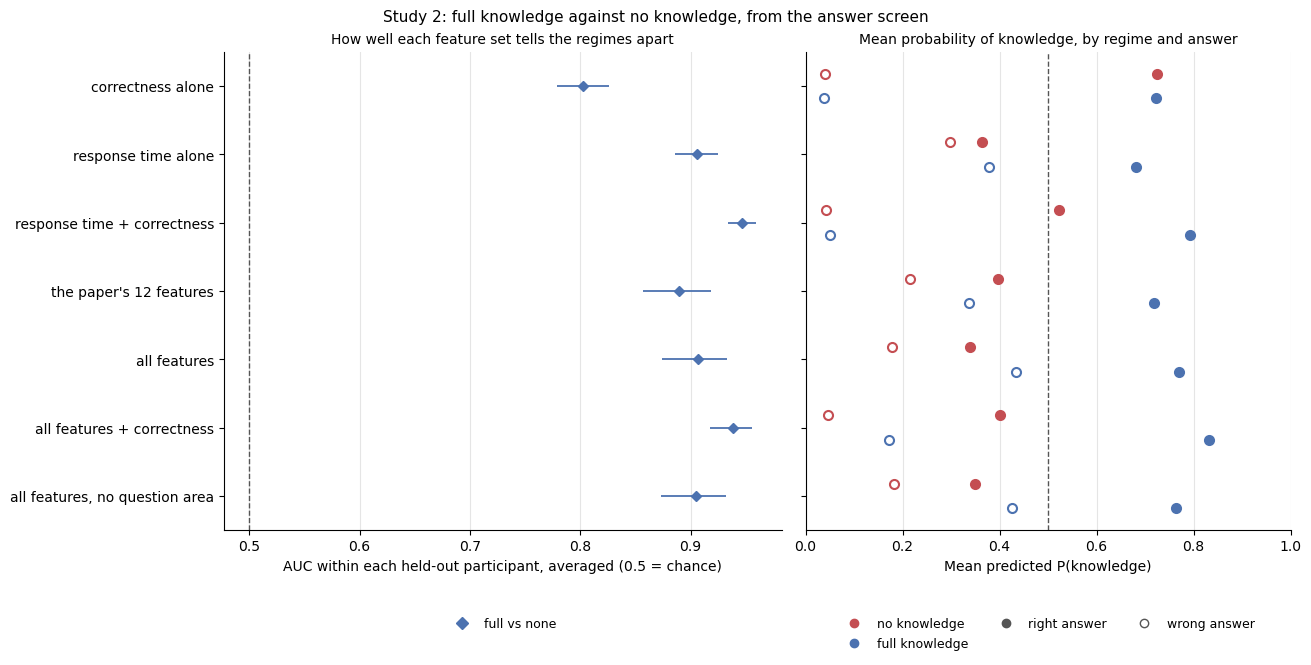

In [5]:
tables["probabilities"] = R.probability_table(preds)
fig = R.plot_detection(tables["scores"], tables["probabilities"], dict(tables))

### The errors
*`run.confusion_table`, `run.plot_confusion`*

What each model said at its own cut-off, by regime and by whether the answer was right. No
knowledge belongs in the left column, full knowledge in the right; the titles give the accuracy
and the balanced accuracy. Wrong answers and known answers mostly sort themselves. The row to
watch is the right answers given without knowledge.

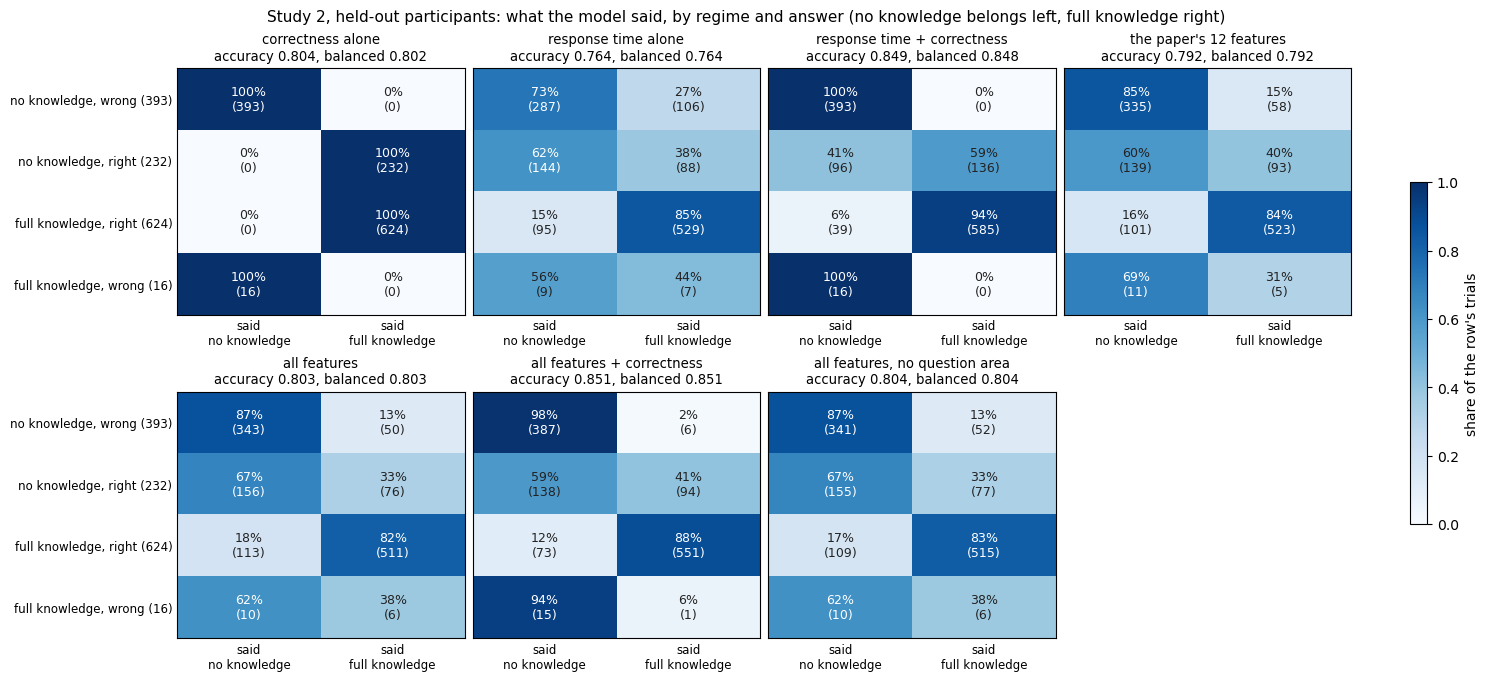

In [6]:
fig = R.plot_confusion(R.confusion_table(preds))

### The probabilities
*`run.histogram_table`, `run.plot_histograms`*

The predicted probability of full knowledge, a histogram per regime and answer, each as shares
of its own trials. The 16 wrong answers given with full knowledge are ticks, one per trial.

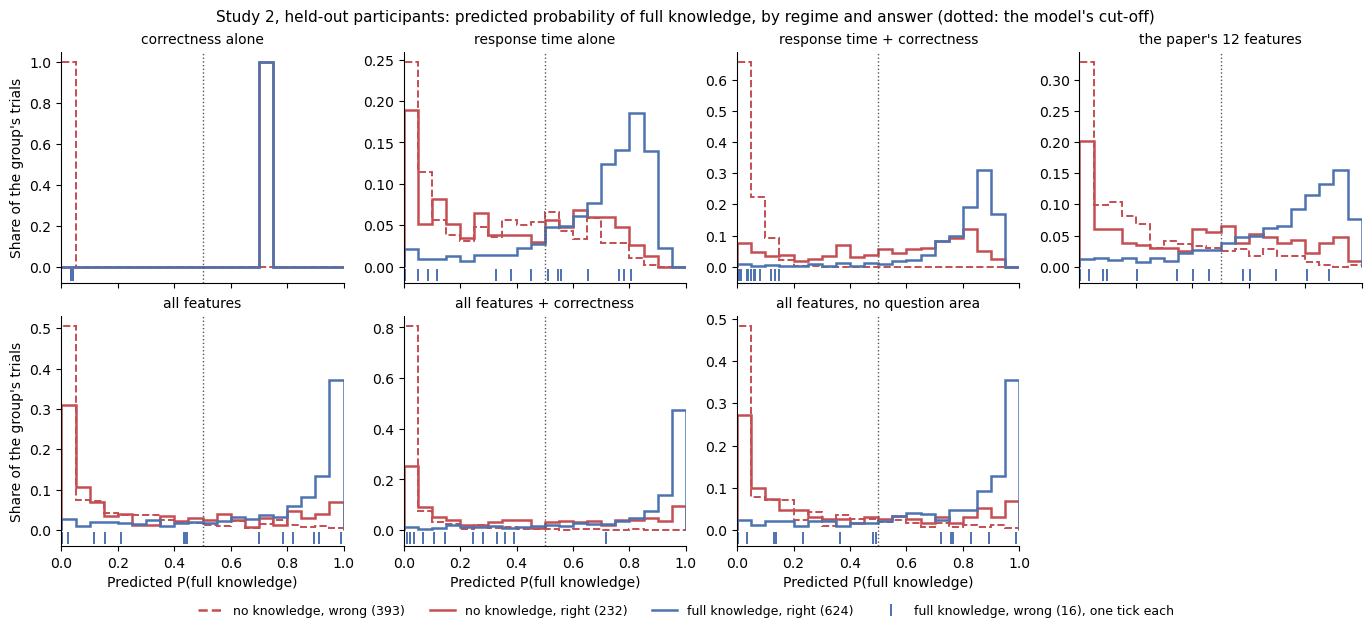

In [7]:
fig = R.plot_histograms(R.histogram_table(preds), preds)

### Which single features carry it
*`run.feature_auc`*

Each feature on its own, ranked by how far its AUC is from 0.5. Below 0.5, lower values go with
full knowledge.

In [8]:
R.feature_auc(trials, sets["all_features"]).head(15).round(3)

,feature,auc,n_trials
0,total_answering_RT_normalized,0.136,1265
1,RT_normalized_wrong_mean,0.146,1265
2,trial_mean_dwell,0.153,1265
3,mean_dwell_time__wrong_mean,0.157,1265
4,TFD_normalized_wrong_mean,0.157,1265
5,mean_fixations_count__wrong_mean,0.168,1265
6,TimeSinceOffset_normalized_wrong_mean,0.169,1265
7,RT_pure_question,0.172,1265
8,RT_normalized_question,0.173,1265
9,RT_pure_wrong_mean,0.174,1265


## 4. Right answers only: known, or a lucky guess?
*`guesses.py`*

These are the trials that matter: right answers given without knowledge, against right answers
given with full knowledge. Two changes to the setup above are tried, alone and together:

* **Training on right answers only**, so the model learns only what separates a guess from a
  known answer.
* **Centring each feature within the person**: its distance from the person's own mean, over all
  their trials here, right and wrong. People differ in pace, so a quick guesser looks like a
  knower. It uses no labels, but in use it needs a batch of trials from the person. Pupil size and
  first-fixation duration are left as measured, since they have missing values.

Every variant is scored on the same right answers of the same held-out participants.

In [9]:
guess_preds = G.guess_predictions(trials, sets)
guess = R.score_tables(guess_preds, pairs=G.GUESS_PAIRS)
guess |= G.cutoff_tables(guess_preds)
display(guess["scores"].set_index("feature_set")[["person_auc", "pooled_auc"]]
        .join(guess["cutoff"].set_index("feature_set")[["guesses_called_guesses", "known_called_known",
                                                         "balanced_accuracy"]])
        .round(3))
display(guess["pairs"][["question", "person_auc_difference", "person_p", "pooled_auc_difference", "pooled_p"]].round(4))
display(guess["cutoff_pairs"][["question", "guesses_called_guesses_difference", "balanced_accuracy_difference",
                               "balanced_accuracy_p"]].round(4))

centred per person: 127 of 177 columns; left as measured (have missing values): ['first_encounter_avg_pupil_size_z__answer_A', 'first_encounter_avg_pupil_size_z__answer_B', 'first_encounter_avg_pupil_size_z__answer_C', 'first_encounter_avg_pupil_size_z__answer_D', 'first_encounter_avg_pupil_size_z__contrast', 'first_encounter_avg_pupil_size_z__correct', 'first_encounter_avg_pupil_size_z__distance_closest', 'first_encounter_avg_pupil_size_z__distance_furthest', 'first_encounter_avg_pupil_size_z__question', 'first_encounter_avg_pupil_size_z__wrong_mean', 'mean_avg_fix_pupil_size_z__answer_A', 'mean_avg_fix_pupil_size_z__answer_B', 'mean_avg_fix_pupil_size_z__answer_C', 'mean_avg_fix_pupil_size_z__answer_D', 'mean_avg_fix_pupil_size_z__contrast', 'mean_avg_fix_pupil_size_z__correct', 'mean_avg_fix_pupil_size_z__distance_closest', 'mean_avg_fix_pupil_size_z__distance_furthest', 'mean_avg_fix_pupil_size_z__question', 'mean_avg_fix_pupil_size_z__wrong_mean', 'mean_first_fixation_duration__an

,person_auc,pooled_auc,guesses_called_guesses,known_called_known,balanced_accuracy
feature_set,,,,,
response_time|all|raw,0.896,0.826,0.621,0.848,0.734
paper_model|all|raw,0.830,0.796,0.599,0.838,0.719
all_features|all|raw,0.865,0.825,0.672,0.819,0.746
response_time|right|raw,0.898,0.823,0.677,0.806,0.741
paper_model|right|raw,0.859,0.826,0.690,0.811,0.750
all_features|right|raw,0.859,0.826,0.698,0.801,0.750
response_time|all|centred,0.899,0.881,0.720,0.865,0.793
paper_model|all|centred,0.848,0.840,0.664,0.848,0.756
all_features|all|centred,0.882,0.878,0.733,0.849,0.791


,question,person_auc_difference,person_p,pooled_auc_difference,pooled_p
0,"training on right answers only, all features",-0.0054,0.5560,0.0007,0.9940
1,"training on right answers only, response time",0.0023,0.3660,-0.0031,0.4050
2,"centring per person, all features",0.0176,0.1000,0.0529,0.0100
3,"centring per person, response time",0.0031,0.0710,0.0546,0.0290
4,"both changes, all features",0.0137,0.2780,0.0481,0.0140
5,"both changes, the paper's features",0.0465,0.0005,0.0619,0.0005
6,"what gaze adds to response time, with both cha...",-0.0203,0.3000,-0.0081,0.6310


,question,guesses_called_guesses_difference,balanced_accuracy_difference,balanced_accuracy_p
0,"training on right answers only, all features",0.0259,0.0041,0.7660
1,"training on right answers only, response time",0.0560,0.0072,0.4900
2,"centring per person, all features",0.0603,0.0454,0.1050
3,"centring per person, response time",0.0991,0.0584,0.0020
4,"both changes, all features",0.0862,0.0519,0.0150
5,"both changes, the paper's features",0.1638,0.0723,0.0005
6,"what gaze adds to response time, with both cha...",-0.0043,-0.0038,0.8900


Left, the within-person AUC: how well each person's known answers are put above their guesses.
Right, at the model's cut-off, the share of guesses called guesses, of known answers called known,
and their mean. Calling more answers guesses raises the first share and lowers the second, so the
variants compare on the AUC and the balanced accuracy.

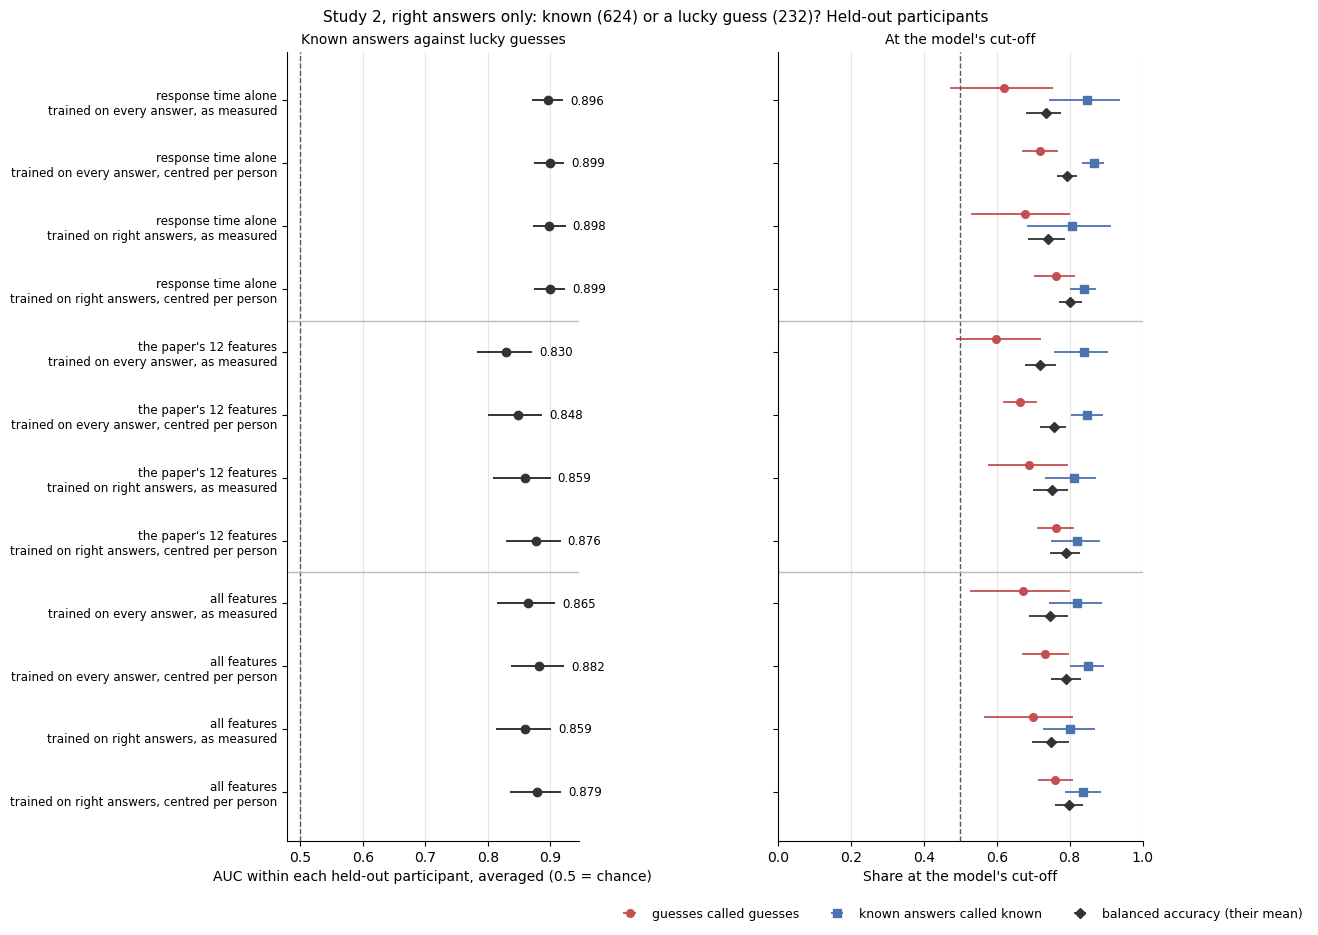

In [10]:
fig = G.plot_guesses(guess["scores"], guess["cutoff"], dict(guess))

### The errors
*`guesses.plot_guess_confusion`*

Guesses belong in the left column, known answers in the right. The titles give the accuracy and
balanced accuracy on these right answers; the accuracy leans towards the known answers, which are
nearly three in four of them.

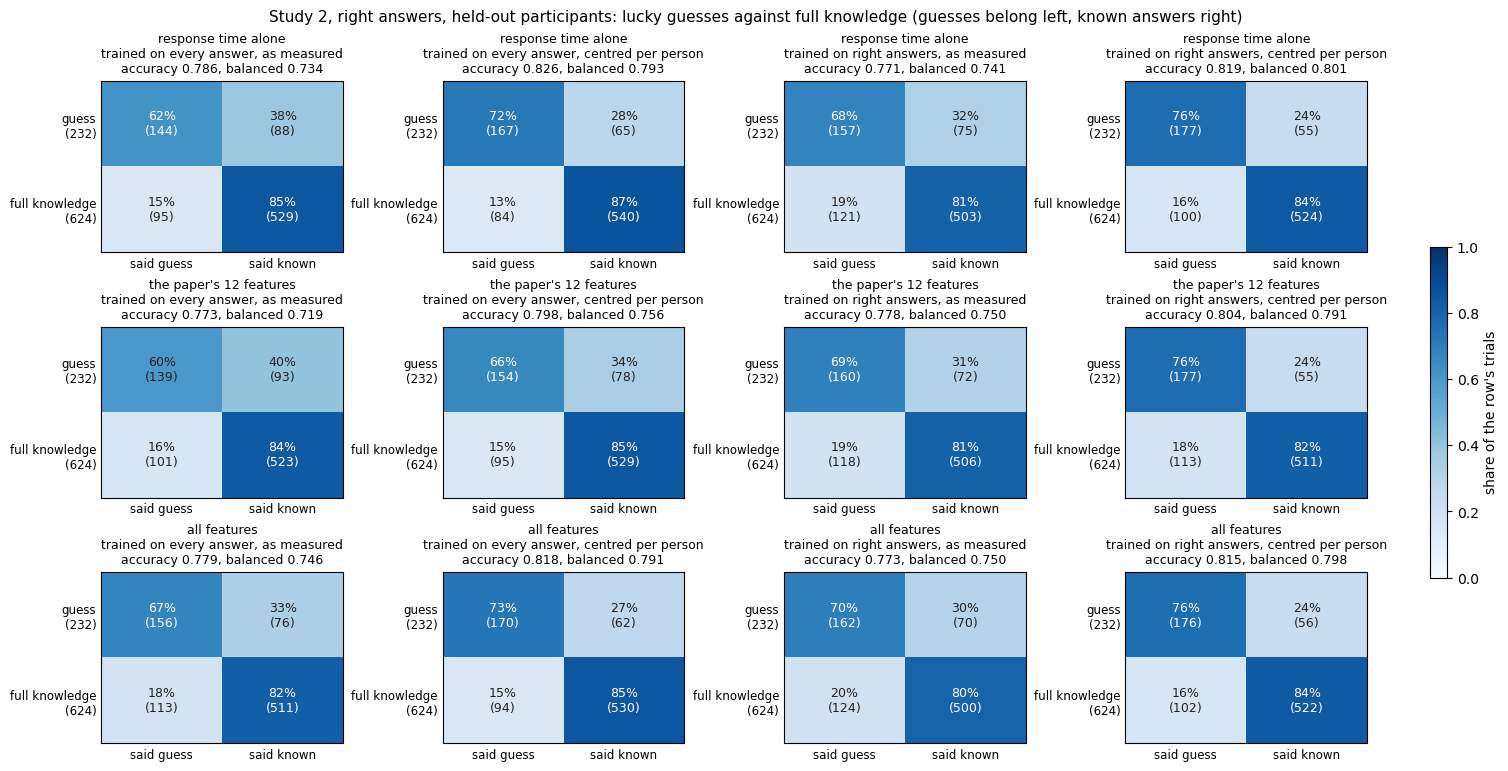

In [11]:
fig = G.plot_guess_confusion(R.confusion_table(guess_preds))

### The probabilities
*`guesses.plot_guess_histograms`*

Lucky guesses (red) and known answers (blue), each as shares of its own trials. The y scales
differ between panels.

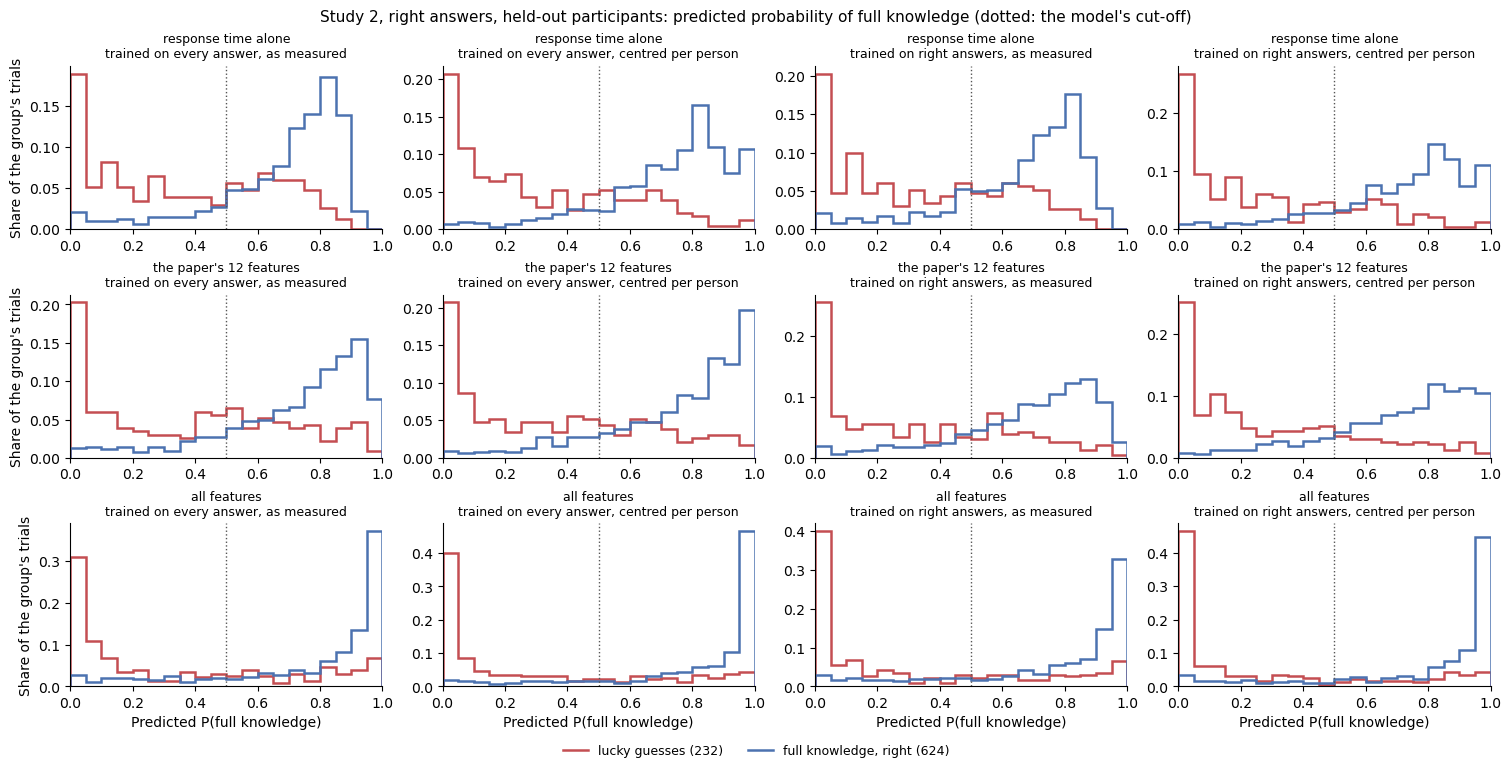

In [12]:
fig = G.plot_guess_histograms(R.histogram_table(guess_preds))

## 5. Does the eye tracker beat a stopwatch?

Response time needs no eye tracker. Two places ask whether the eye tracker adds to it.

### Correctness, with the answer hidden
*`explorations/answer_hidden/tracker.py`, read from its saved tables*

The correctness model without the answer key: what needs no eye tracker (`no_tracker`: the
response times and the presses), the eye tracker without its time measures
(`gaze_wide_no_time`), and the two together. The first table is the balanced accuracy of each
set; the second the paired tests on Study 1's held-out kinds and Study 2's regimes. Written by
`python -m src.explorations.answer_hidden.tracker`, so it is as current as that run.

In [13]:
from src.lib.plotting.output import analysis_dir
hidden = analysis_dir("explorations/answer_hidden") / "tables" / "logreg"
display(pd.read_csv(hidden / "deliberation_search__search-tracker__scores.csv")
        .drop(columns=["model_family", "with base"]).round(3))
display(pd.read_csv(hidden / "tracker_added_value__differences.csv")
        [["dataset", "test", "question", "auc_diff", "auc_p", "bacc_diff", "bacc_p"]].round(4))

,model,n_features,l1: new_item,l1: new_subject,l1: both,l1: average,knowqa: no knowledge,knowqa: partial knowledge,knowqa: full knowledge,knowqa: all
0,no_tracker_time,1,0.641,0.641,0.645,0.642,0.553,0.609,0.704,0.694
1,no_tracker,4,0.647,0.646,0.654,0.649,0.538,0.633,0.721,0.706
2,chosen,12,0.649,0.649,0.652,0.650,0.556,0.655,0.713,0.703
3,chosen_tracker_only,11,0.642,0.645,0.638,0.642,0.527,0.632,0.695,0.682
4,chosen_no_time,7,0.640,0.639,0.632,0.637,0.522,0.640,0.666,0.663
5,gaze_wide_tracker_only,20,0.648,0.648,0.641,0.646,0.529,0.622,0.702,0.667
6,gaze_wide_no_time,18,0.644,0.643,0.635,0.641,0.531,0.614,0.669,0.662
7,gaze_wide_no_time+no_tracker,22,0.657,0.655,0.651,0.654,0.529,0.618,0.692,0.680


,dataset,test,question,auc_diff,auc_p,bacc_diff,bacc_p
0,l1,new_item,gaze (no time) added to the no-tracker features,0.0077,0.0150,0.0097,0.0010
1,l1,new_item,the chosen set against the no-tracker features,-0.0024,0.4960,0.0022,0.5720
2,l1,new_item,the no-tracker features added to gaze (no time),0.0149,0.0005,0.0121,0.0010
3,l1,new_subject,gaze (no time) added to the no-tracker features,0.0057,0.0870,0.0084,0.0070
4,l1,new_subject,the chosen set against the no-tracker features,0.0000,0.9690,0.0027,0.4990
5,l1,new_subject,the no-tracker features added to gaze (no time),0.0143,0.0005,0.0119,0.0005
6,l1,both,gaze (no time) added to the no-tracker features,-0.0022,0.7030,-0.0035,0.5670
7,l1,both,the chosen set against the no-tracker features,-0.0073,0.1860,-0.0028,0.6940
8,l1,both,the no-tracker features added to gaze (no time),0.0180,0.0005,0.0163,0.0030
9,knowqa,no knowledge,gaze (no time) added to the no-tracker features,-0.0092,0.1970,-0.0089,0.3380


### Knowledge, with and without the answer key
*`answer_free.py`*

The gaze features of section 3 know which answer is correct, so they can read off whether the
answer was right, and that alone separates the regimes well. Here they are rebuilt without
the key: each per-answer measure becomes its largest, average and smallest value over the four
answers, and the comparisons with the correct answer and the last-look-by-letter columns are
dropped. The first table says what became of each column.

Two models, each knowledge regime against none, with the other one left out. Partial
knowledge comes back here, whatever `run.WITH_KNOWLEDGE` says, because the paragraph-reading
regime is where the eye tracker might add something.

In [14]:
frame, af_sets, fate = AF.answer_free_sets(every_regime)
display(fate["fate"].value_counts())
af_preds = AF.predictions(frame, af_sets)
af = AF.score(af_preds)
display(af["scores"][["feature_set", "comparison", "person_auc", "person_ci_low", "person_ci_high",
                      "pooled_auc", "balanced_accuracy"]].round(3))
display(af["pairs"][["question", "comparison", "person_auc_difference", "person_ci_low", "person_ci_high",
                     "person_p", "pooled_p"]].round(4))

fate
dropped: uses the key       80
spread over the answers     64
kept                        23
dropped: names an answer     6
response time                3
Name: count, dtype: int64

,feature_set,comparison,person_auc,person_ci_low,person_ci_high,pooled_auc,balanced_accuracy
0,response_time,partial vs none,0.694,0.661,0.728,0.665,0.613
1,response_time+correctness,partial vs none,0.774,0.751,0.797,0.758,0.716
2,gaze_no_key,partial vs none,0.758,0.680,0.817,0.746,0.681
3,gaze_no_key+time,partial vs none,0.763,0.693,0.817,0.748,0.685
4,gaze_no_key+time+correctness,partial vs none,0.817,0.761,0.862,0.803,0.728
5,all_features,partial vs none,0.775,0.715,0.825,0.760,0.697
6,response_time,full vs none,0.906,0.886,0.925,0.850,0.764
7,response_time+correctness,full vs none,0.947,0.934,0.960,0.916,0.848
8,gaze_no_key,full vs none,0.898,0.862,0.929,0.867,0.791
9,gaze_no_key+time,full vs none,0.899,0.863,0.930,0.868,0.793


,question,comparison,person_auc_difference,person_ci_low,person_ci_high,person_p,pooled_p
0,"the eye tracker alone, without the key, agains...",partial vs none,0.0635,0.0048,0.1123,0.029,0.004
1,what the eye tracker without the key adds to time,partial vs none,0.0684,0.0156,0.1133,0.008,0.002
2,what the eye tracker without the key adds to t...,partial vs none,0.0429,-0.0006,0.0761,0.053,0.033
3,what knowing the answer key adds to the eye tr...,partial vs none,0.0118,-0.0056,0.0306,0.193,0.235
4,"the eye tracker alone, without the key, agains...",full vs none,-0.0082,-0.0415,0.0221,0.607,0.354
5,what the eye tracker without the key adds to time,full vs none,-0.0069,-0.0410,0.0238,0.662,0.359
6,what the eye tracker without the key adds to t...,full vs none,-0.0045,-0.0249,0.0152,0.640,0.562
7,what knowing the answer key adds to the eye tr...,full vs none,0.0072,-0.0016,0.0152,0.118,0.039


Each feature set's within-person AUC, for partial knowledge against none (orange) and full
against none (blue). The eye tracker is set against response time with and without
correctness, and the last row has the answer key back.

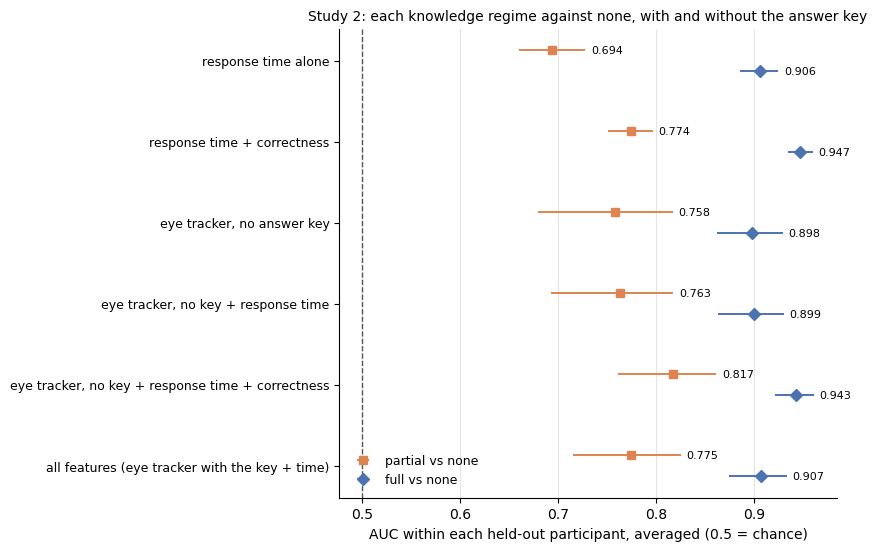

In [15]:
fig = AF.plot_answer_free(af["scores"], dict(af))